In [ ]:

# ==========================================
# PUMP CONDITION CLASSIFICATION
# Fundamentals of Machine Learning - Classwork 3.12
# ==========================================


# ==========================================

# GROUP MEMBERS AND ID NUMBERS
# ==========================================
# - MAHLET CHANYALEW ----- WOUR/3963/16
# - AMMAR ABDURAHMAN ----- WOUR/0244/16 
# - ELSA DEGU ------------ WOUR/0657/16

# ==========================================

# 1. Import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


In [2]:
# 2. Create an illustrative pump dataset

np.random.seed(42)

number_of_records = 1500

data = pd.DataFrame({
    "Vibration": np.random.uniform(1, 10, number_of_records),
    "RPM": np.random.uniform(1000, 2500, number_of_records),
    "Temperature": np.random.uniform(30, 120, number_of_records),
    "Pressure": np.random.uniform(20, 100, number_of_records),
    "Operating_Hours": np.random.uniform(100, 10000, number_of_records)
})

In [ ]:
# 3. Create illustrative labels

risk_score = (
    0.45 * (data["Vibration"] / 10) +
    0.35 * (data["Temperature"] / 120) +
    0.10 * (abs(data["RPM"] - 1800) / 500) +
    0.10 * (100 - data["Pressure"]) / 80
)

data["Condition"] = pd.qcut(
    risk_score,
    q=3,
    labels=["Normal", "Warning", "Fault"]
)

print("First five records:")
print(data.head())

print("\nClass distribution:")
print(data["Condition"].value_counts())


First five records:
   Vibration          RPM  Temperature   Pressure  Operating_Hours Condition
0   4.370861  1778.622678    90.543269  67.943943      6517.743845    Normal
1   9.556429  1718.772816   101.701326  61.096628      1806.624985     Fault
2   7.587945  1038.463099    52.542111  43.054762      8736.706177     Fault
3   6.387926  1511.871741    86.238669  20.517149      6169.850767     Fault
4   2.404168  1570.293428    81.457138  59.699138      1656.318447    Normal

Class distribution:
Condition
Normal     500
Warning    500
Fault      500
Name: count, dtype: int64


In [4]:
# 4. Separate features and target

X = data.drop("Condition", axis=1)

y = data["Condition"]


In [5]:
# 5. Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 1200
Testing records: 300


In [6]:
# 6. Create classification models

models = {

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "SVM": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf")
    ),

    "Naive Bayes": make_pipeline(
        StandardScaler(),
        GaussianNB()
    ),

    "AdaBoost": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1),
        n_estimators=100,
        learning_rate=0.5,
        random_state=42
    )
}

In [7]:
# 7. Train and evaluate the models

results = []

class_labels = ["Normal", "Warning", "Fault"]

for name, model in models.items():

    # Train model
    model.fit(X_train, y_train)

    # Make predictions
    predictions = model.predict(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, predictions)

    precision_fault = precision_score(
        y_test,
        predictions,
        labels=["Fault"],
        average="macro",
        zero_division=0
    )

    recall_fault = recall_score(
        y_test,
        predictions,
        labels=["Fault"],
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    )

    # Save results
    results.append({
        "Algorithm": name,
        "Accuracy": accuracy,
        "Fault Precision": precision_fault,
        "Fault Recall": recall_fault,
        "Macro F1": macro_f1
    })

    print("\n================================")
    print(name)
    print("================================")

    print("Accuracy:", round(accuracy, 4))
    print("Fault Precision:", round(precision_fault, 4))
    print("Fault Recall:", round(recall_fault, 4))
    print("Macro F1:", round(macro_f1, 4))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        predictions,
        zero_division=0
    ))




Decision Tree
Accuracy: 0.8033
Fault Precision: 0.883
Fault Recall: 0.83
Macro F1: 0.806

Classification Report:
              precision    recall  f1-score   support

       Fault       0.88      0.83      0.86       100
      Normal       0.87      0.81      0.84       100
     Warning       0.68      0.77      0.72       100

    accuracy                           0.80       300
   macro avg       0.81      0.80      0.81       300
weighted avg       0.81      0.80      0.81       300


Random Forest
Accuracy: 0.8967
Fault Precision: 0.9293
Fault Recall: 0.92
Macro F1: 0.8965

Classification Report:
              precision    recall  f1-score   support

       Fault       0.93      0.92      0.92       100
      Normal       0.91      0.93      0.92       100
     Warning       0.85      0.84      0.84       100

    accuracy                           0.90       300
   macro avg       0.90      0.90      0.90       300
weighted avg       0.90      0.90      0.90       300


SVM
Acc

In [8]:
# 8. Compare all algorithms

results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON")
print(results_df.to_string(index=False))


MODEL COMPARISON
    Algorithm  Accuracy  Fault Precision  Fault Recall  Macro F1
Decision Tree  0.803333         0.882979          0.83  0.806018
Random Forest  0.896667         0.929293          0.92  0.896545
          SVM  0.930000         0.941748          0.97  0.929522
  Naive Bayes  0.813333         0.910000          0.91  0.812670
     AdaBoost  0.803333         0.943182          0.83  0.807689


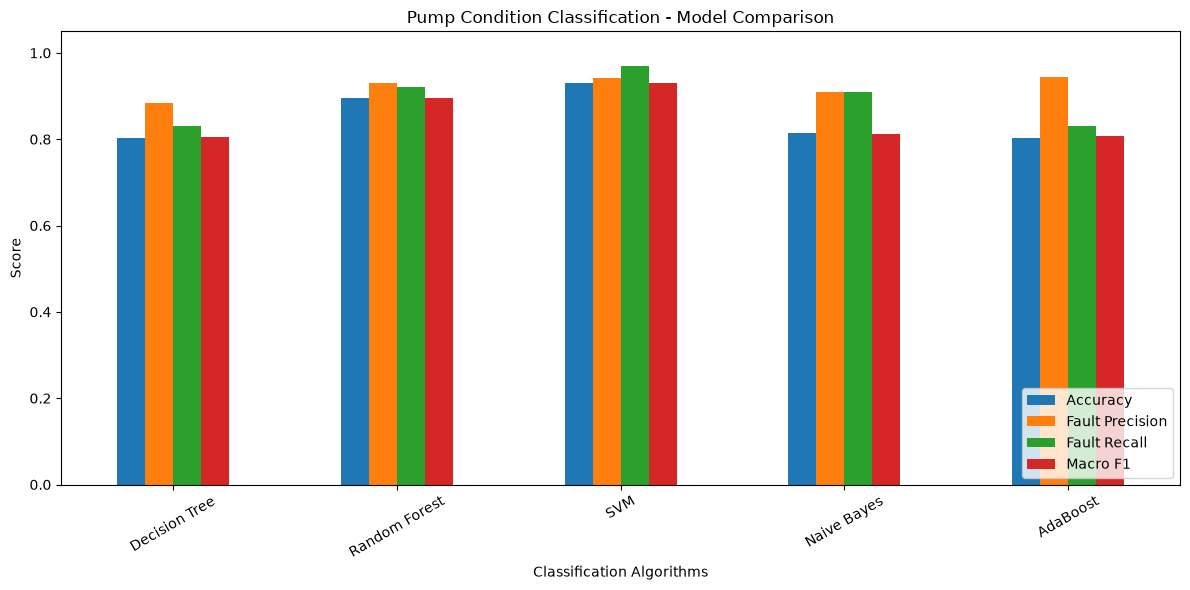

In [9]:
# 9. Visualize model performance

results_df.set_index("Algorithm")[
    ["Accuracy", "Fault Precision", "Fault Recall", "Macro F1"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Pump Condition Classification - Model Comparison")
plt.ylabel("Score")
plt.xlabel("Classification Algorithms")
plt.ylim(0, 1.05)
plt.xticks(rotation=30)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


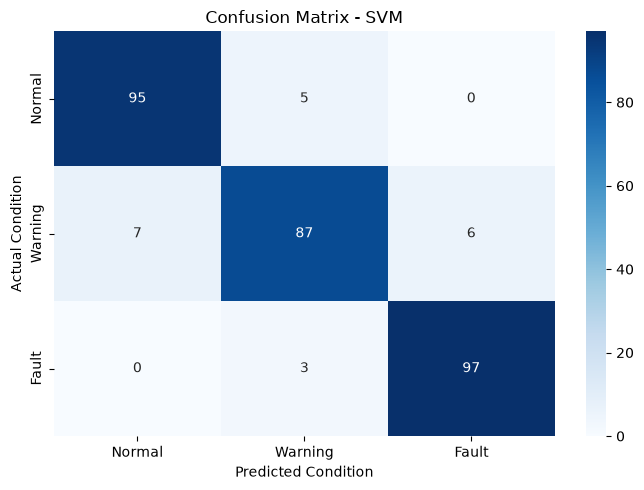

In [10]:
# 10. Confusion matrix for the best model

best_model_name = results_df.loc[
    results_df["Macro F1"].idxmax(),
    "Algorithm"
]

best_model = models[best_model_name]

best_predictions = best_model.predict(X_test)

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=class_labels
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title("Confusion Matrix - " + best_model_name)
plt.xlabel("Predicted Condition")
plt.ylabel("Actual Condition")
plt.tight_layout()
plt.show()


In [11]:
# 11. Predict a new pump condition

new_pump = pd.DataFrame([{
    "Vibration": 8.5,
    "RPM": 2200,
    "Temperature": 105,
    "Pressure": 35,
    "Operating_Hours": 8500
}])

prediction = best_model.predict(new_pump)

print("\nNEW PUMP PREDICTION")
print("Predicted Condition:", prediction[0])

print("\nSelected Model:", best_model_name)



NEW PUMP PREDICTION
Predicted Condition: Fault

Selected Model: SVM
